# Section 2: Data Description and Exploratory Analysis

We examine parking occupancy and its potential predictors before developing the regression models.

<a id="section-2a"></a>

## 2(a) Dataset Description

The dataset contains one observation per LADOT sensor-equipped metered parking space. The outcome is the fraction of retained valid time occupied during August 2025. It is calculated from occupied minutes rather than the share of sensor records marked occupied. The cleaning excludes UNKNOWN-start intervals and gaps longer than 24 hours, and retains spaces with transactions on at least 25 calendar days. Active days do not imply continuous monitoring.

The occupancy file contains 4,185 spaces, of which 4,139 match the meter inventory. We use the 4,060 FLAT and TOD spaces for the main analysis. The 79 JUMP spaces are excluded because their price midpoint mixes hourly and multi-hour charges. The 44 spaces with missing income remain in the exploratory sample; the later regression comparison uses 4,016 complete cases.

Occupancy is from August 2025, but meter prices and business registrations are October 2026 snapshots. Neighborhood measures come from the 2024 ACS five-year release, covering 2020–2024, and 2024 tract boundaries and land areas. These different dates limit how closely the predictors describe conditions during the occupancy month. The references identify the source datasets; the accompanying Python source documents construction and matching.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown, HTML

root = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
             if (folder / "data/processed/parking_cross_section.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("The project data/processed/parking_cross_section.csv file is required.")

parking_full = pd.read_csv(
    root / "data/processed/parking_cross_section.csv",
    dtype={"SpaceID": str, "GEOID": str}
)
parking = parking_full[parking_full["RateType"].isin(["FLAT", "TOD"])].copy()
dependent_variable = "occupancy_rate"

candidate_variables = [
    "price_midpoint", "time_limit_hours", "population_density", "median_income",
    "nearby_restaurant_retail_count", "drive_alone_share", "RateType", "MeterType",
    "housing_density", "transit_share", "walk_share", "nearby_business_count"
]

print("Original spaces:", len(parking_full))
print("FLAT and TOD spaces:", len(parking))
print("Spaces with observed income:", parking["median_income"].notna().sum())
parking["RateType"].value_counts()

# Preserve complete table text in report outputs.
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)


Original spaces: 4139
FLAT and TOD spaces: 4060
Spaces with observed income: 4016


In [2]:
measurement_table_1 = pd.DataFrame([['Los Angeles Department of Transportation sensor archive and meter inventory', 'Space-level occupancy, price/rate structure, time limits, meter technology and coordinates in Los Angeles', 'August 2025 occupancy; October 2026 inventory snapshot'], ['U.S. Census Bureau ACS, TIGER/Line and Gazetteer', 'Los Angeles County tract population, housing, income, resident commuting, containing tract and land area', 'ACS 2024 five-year release (2020–2024); 2024 geography'], ['Los Angeles Office of Finance business registry', 'Located registered accounts within 0.25 miles of a parking space; all businesses and NAICS 722/44–45 subset', 'October 2026 snapshot']], columns=['Source', 'Variables and geographic coverage', 'Period'])
display(HTML(measurement_table_1.to_html(index=False, escape=True, max_rows=None, max_cols=None, border=0)))


Source,Variables and geographic coverage,Period
Los Angeles Department of Transportation sensor archive and meter inventory,"Space-level occupancy, price/rate structure, time limits, meter technology and coordinates in Los Angeles",August 2025 occupancy; October 2026 inventory snapshot
"U.S. Census Bureau ACS, TIGER/Line and Gazetteer","Los Angeles County tract population, housing, income, resident commuting, containing tract and land area",ACS 2024 five-year release (2020–2024); 2024 geography
Los Angeles Office of Finance business registry,Located registered accounts within 0.25 miles of a parking space; all businesses and NAICS 722/44–45 subset,October 2026 snapshot


The final event for a space is not extended to month-end. Valid durations are calculated to the next recorded event before UNKNOWN states are excluded, so the procedure does not bridge across an UNKNOWN interval. Exact-duplicate inventory records are removed before matching. Tract assignment uses containing polygons, and business buffers use projected distances; no missing zoning assignment is replaced with a neighboring parcel. Public source references appear at the end of the report.

In [3]:
measurement_table_2 = pd.DataFrame([['occupancy_rate', 'Occupied minutes divided by retained valid minutes; a fraction from 0 to 1'], ['price_midpoint', 'Stated hourly price for FLAT meters; midpoint of hourly rate endpoints for TOD meters, in dollars'], ['time_limit_hours', 'Posted time limit mapped to hours'], ['population_density', 'People per square mile of tract land'], ['housing_density', 'Housing units per square mile of tract land'], ['median_income', 'Tract median household income in 2024 dollars'], ['drive_alone_share, transit_share, walk_share', 'Share of resident workers using each mode; the denominator includes workers at home'], ['nearby_restaurant_retail_count', 'Located food-service, drinking-place and retail registrations within 0.25 miles; NAICS 722 and 44–45'], ['nearby_business_count', 'All located business registrations within 0.25 miles'], ['RateType', 'FLAT or TOD pricing structure'], ['MeterType', 'Single-space or multi-space meter']], columns=['Variable', 'Definition and units'])
display(HTML(measurement_table_2.to_html(index=False, escape=True, max_rows=None, max_cols=None, border=0)))


Variable,Definition and units
occupancy_rate,Occupied minutes divided by retained valid minutes; a fraction from 0 to 1
price_midpoint,"Stated hourly price for FLAT meters; midpoint of hourly rate endpoints for TOD meters, in dollars"
time_limit_hours,Posted time limit mapped to hours
population_density,People per square mile of tract land
housing_density,Housing units per square mile of tract land
median_income,Tract median household income in 2024 dollars
"drive_alone_share, transit_share, walk_share",Share of resident workers using each mode; the denominator includes workers at home
nearby_restaurant_retail_count,"Located food-service, drinking-place and retail registrations within 0.25 miles; NAICS 722 and 44–45"
nearby_business_count,All located business registrations within 0.25 miles
RateType,FLAT or TOD pricing structure


TOD midpoint is a price proxy, not an observed average payment. Business registrations may share addresses and need not represent distinct operating storefronts. Zoning is excluded from the candidate list because only 49 of the original 4,139 spaces have matched zoning codes.

`RateType_TOD` is 1 for TOD and 0 for the FLAT reference category. `MeterType_Single-Space` is 1 for single-space and 0 for multi-space meters. These are the two indicators created for model comparisons. Commuting-share denominators are resident workers age 16 and over, including those working from home. The `2HR-30MIN` time-limit label is mapped to 2.5 hours; that interpretation is not independently verified.

In [4]:
measurement_table_3 = pd.DataFrame([['SpaceID, BlockFace', 'Source parking-space identifier and block-face label; identifiers, not quantitative predictors'], ['occupied_minutes, total_minutes, active_days', 'Retained occupied minutes, retained valid minutes, and distinct transaction-active calendar days'], ['RateRange, MeteredTimeLimit', 'Original stated price and permitted-duration labels retained for traceability'], ['latitude, longitude', 'Meter coordinates in decimal degrees'], ['GEOID', 'Eleven-character identifier of the containing Census tract'], ['population, housing_units', 'ACS tract totals in people and housing units'], ['commuters, drive_alone, public_transit, walked', 'ACS total workers age 16+ and the corresponding resident commute-mode counts; people'], ['ALAND_SQMI', 'Tract land area, excluding water, in square miles; denominator for population/housing density'], ['zoning_code, zoning_class, zoning_description', 'Available source zoning labels; sparse linkage excludes them from regression'], ['tract_match_status, acs_match_status, zoning_match_status', 'Linkage-status categories used to document geographic and attribute matches']], columns=['Supporting field', 'Definition and units'])
display(HTML(measurement_table_3.to_html(index=False, escape=True, max_rows=None, max_cols=None, border=0)))


Supporting field,Definition and units
"SpaceID, BlockFace","Source parking-space identifier and block-face label; identifiers, not quantitative predictors"
"occupied_minutes, total_minutes, active_days","Retained occupied minutes, retained valid minutes, and distinct transaction-active calendar days"
"RateRange, MeteredTimeLimit",Original stated price and permitted-duration labels retained for traceability
"latitude, longitude",Meter coordinates in decimal degrees
GEOID,Eleven-character identifier of the containing Census tract
"population, housing_units",ACS tract totals in people and housing units
"commuters, drive_alone, public_transit, walked",ACS total workers age 16+ and the corresponding resident commute-mode counts; people
ALAND_SQMI,"Tract land area, excluding water, in square miles; denominator for population/housing density"
"zoning_code, zoning_class, zoning_description",Available source zoning labels; sparse linkage excludes them from regression
"tract_match_status, acs_match_status, zoning_match_status",Linkage-status categories used to document geographic and attribute matches


<a id="section-2b"></a>

## 2(b) Descriptive Statistics

In [5]:
numeric_variables = [
    "occupancy_rate", "price_midpoint", "time_limit_hours", "population_density",
    "median_income", "nearby_restaurant_retail_count", "drive_alone_share",
    "housing_density", "transit_share", "walk_share", "nearby_business_count"
]

indicator_data = pd.get_dummies(parking[["RateType", "MeterType"]], drop_first=True, dtype=int)
descriptive_data = parking[numeric_variables].join(indicator_data)
descriptive = descriptive_data.describe().T[
    ["count", "mean", "50%", "std", "min", "max"]
].rename(columns={"50%": "median"})
descriptive["skewness"] = descriptive_data.skew()
descriptive["excess_kurtosis"] = descriptive_data.kurt()
descriptive["kurtosis"] = descriptive["excess_kurtosis"] + 3
descriptive.round(3)


,count,mean,median,std,min,max,skewness,excess_kurtosis,kurtosis
occupancy_rate,4060.0,0.539,0.539,0.194,0.004,0.999,-0.160,-0.424,2.576
price_midpoint,4060.0,2.092,1.750,1.400,0.500,8.000,1.338,1.873,4.873
time_limit_hours,4060.0,2.446,2.000,0.925,0.250,4.000,0.811,-0.419,2.581
population_density,4060.0,18006.954,14754.902,12710.083,1915.323,132736.842,1.547,7.374,10.374
median_income,4016.0,63083.058,52412.000,29658.373,9375.000,157115.000,1.251,0.942,3.942
nearby_restaurant_retail_count,4060.0,230.007,176.000,148.842,21.000,878.000,1.148,1.336,4.336
drive_alone_share,4060.0,0.417,0.378,0.162,0.089,0.790,0.504,-0.568,2.432
housing_density,4060.0,12335.445,9015.957,9824.718,0.000,101157.895,2.163,10.791,13.791
transit_share,4060.0,0.095,0.071,0.062,0.000,0.271,0.331,-0.962,2.038
walk_share,4060.0,0.141,0.125,0.112,0.000,0.627,1.640,4.218,7.218


In [6]:
category_counts = pd.concat({
    name: parking[name].value_counts(dropna=False).rename("Spaces").to_frame()
    for name in ["RateType", "MeterType"]
}, names=["Variable", "Category"])
display(category_counts)


Spaces
Variable  Category            
RateType  TOD             3323
          FLAT             737
MeterType Single-Space    3927
          Multi-Space      133

Mean occupancy is 0.539, close to its median, so the typical space is occupied for about 54% of its retained observation time. Price, income, density and business counts have longer right tails. Income statistics use 4,016 observed values; the other variables use all 4,060 spaces. Both kurtosis conventions are shown: normal-distribution references are 3 for Pearson kurtosis and 0 for excess kurtosis. The numeric table also includes the TOD and single-space indicators; their means are sample proportions. Category counts are reported separately.

<a id="section-2c"></a>

## 2(c) Histograms, Boxplots, Correlations and Scatterplots

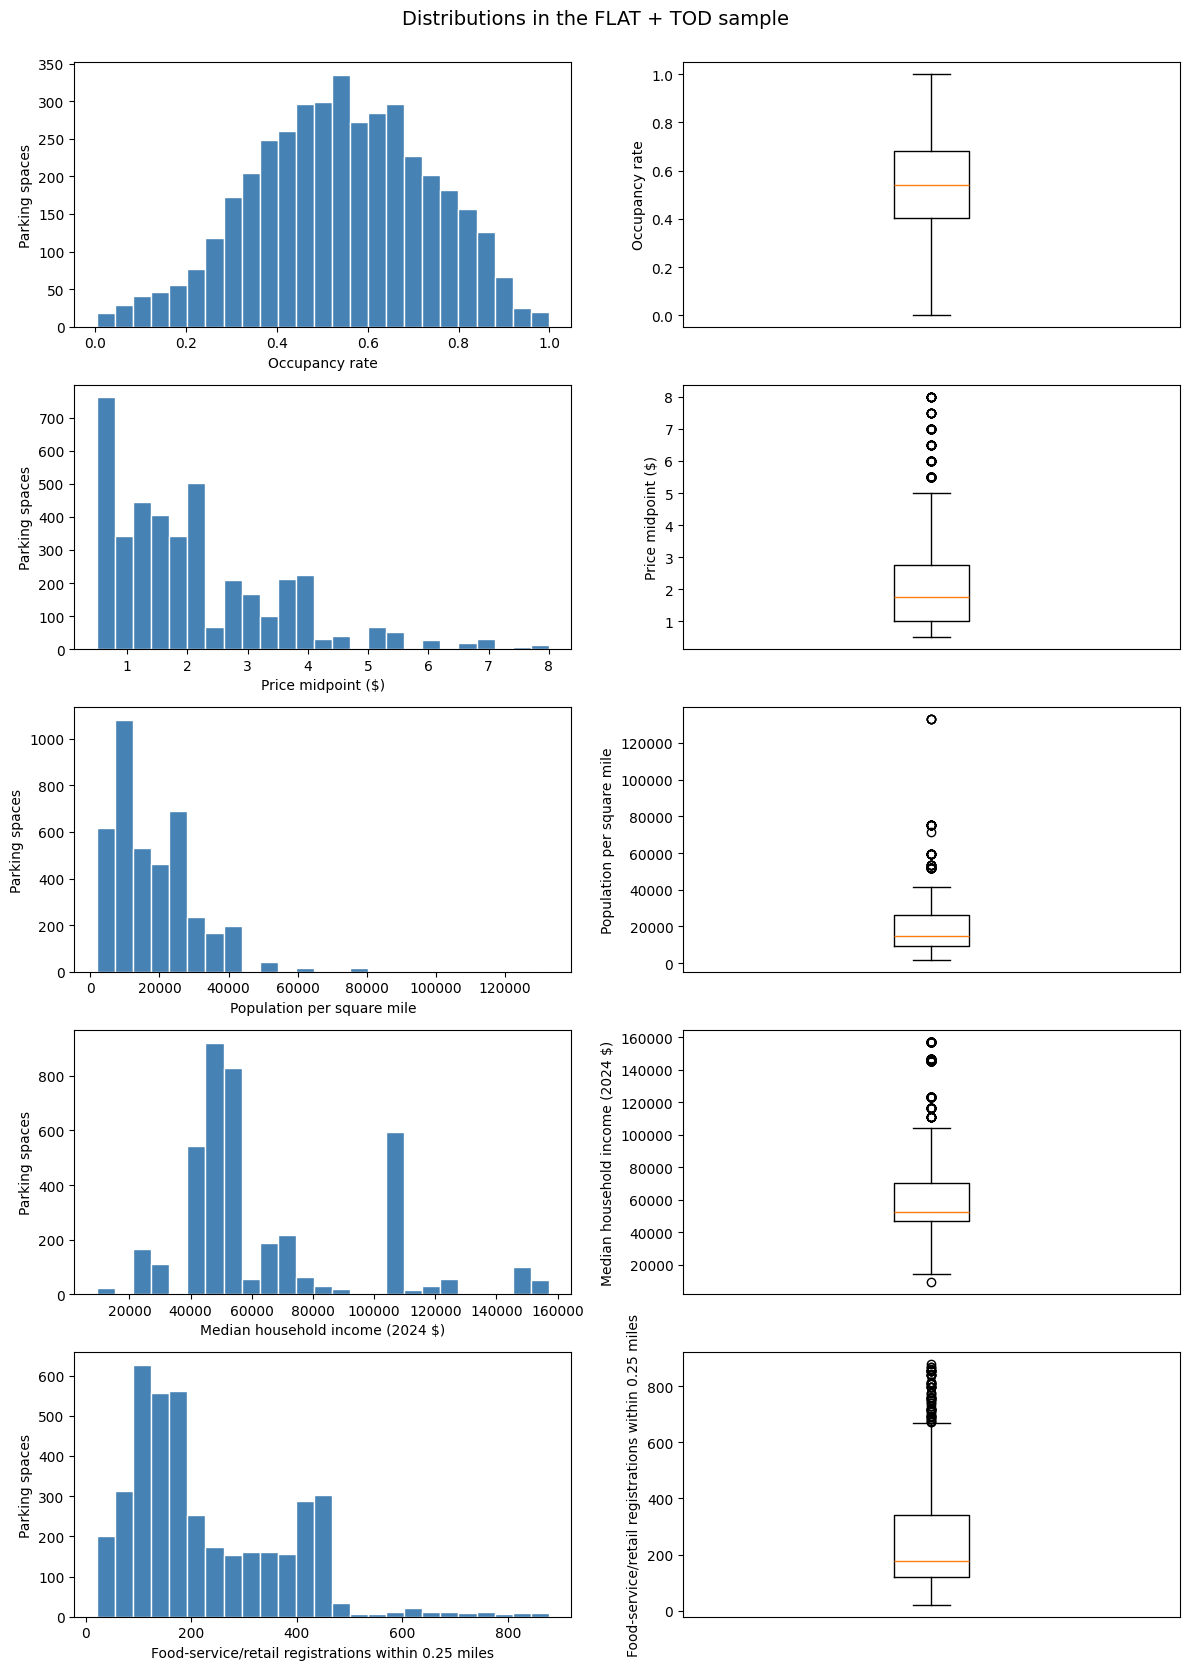

In [7]:
plot_variables = [
    "occupancy_rate", "price_midpoint", "population_density",
    "median_income", "nearby_restaurant_retail_count"
]
plot_labels = [
    "Occupancy rate", "Price midpoint ($)",
    "Population per square mile", "Median household income (2024 $)",
    "Food-service/retail registrations within 0.25 miles"
]

fig, axes = plt.subplots(5, 2, figsize=(12, 17))

for i, variable in enumerate(plot_variables):
    values = parking[variable].dropna()
    axes[i, 0].hist(values, bins=25, color="steelblue", edgecolor="white")
    axes[i, 0].set_xlabel(plot_labels[i])
    axes[i, 0].set_ylabel("Parking spaces")
    axes[i, 1].boxplot(values)
    axes[i, 1].set_ylabel(plot_labels[i])
    axes[i, 1].set_xticks([])

fig.suptitle("Distributions in the FLAT + TOD sample", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

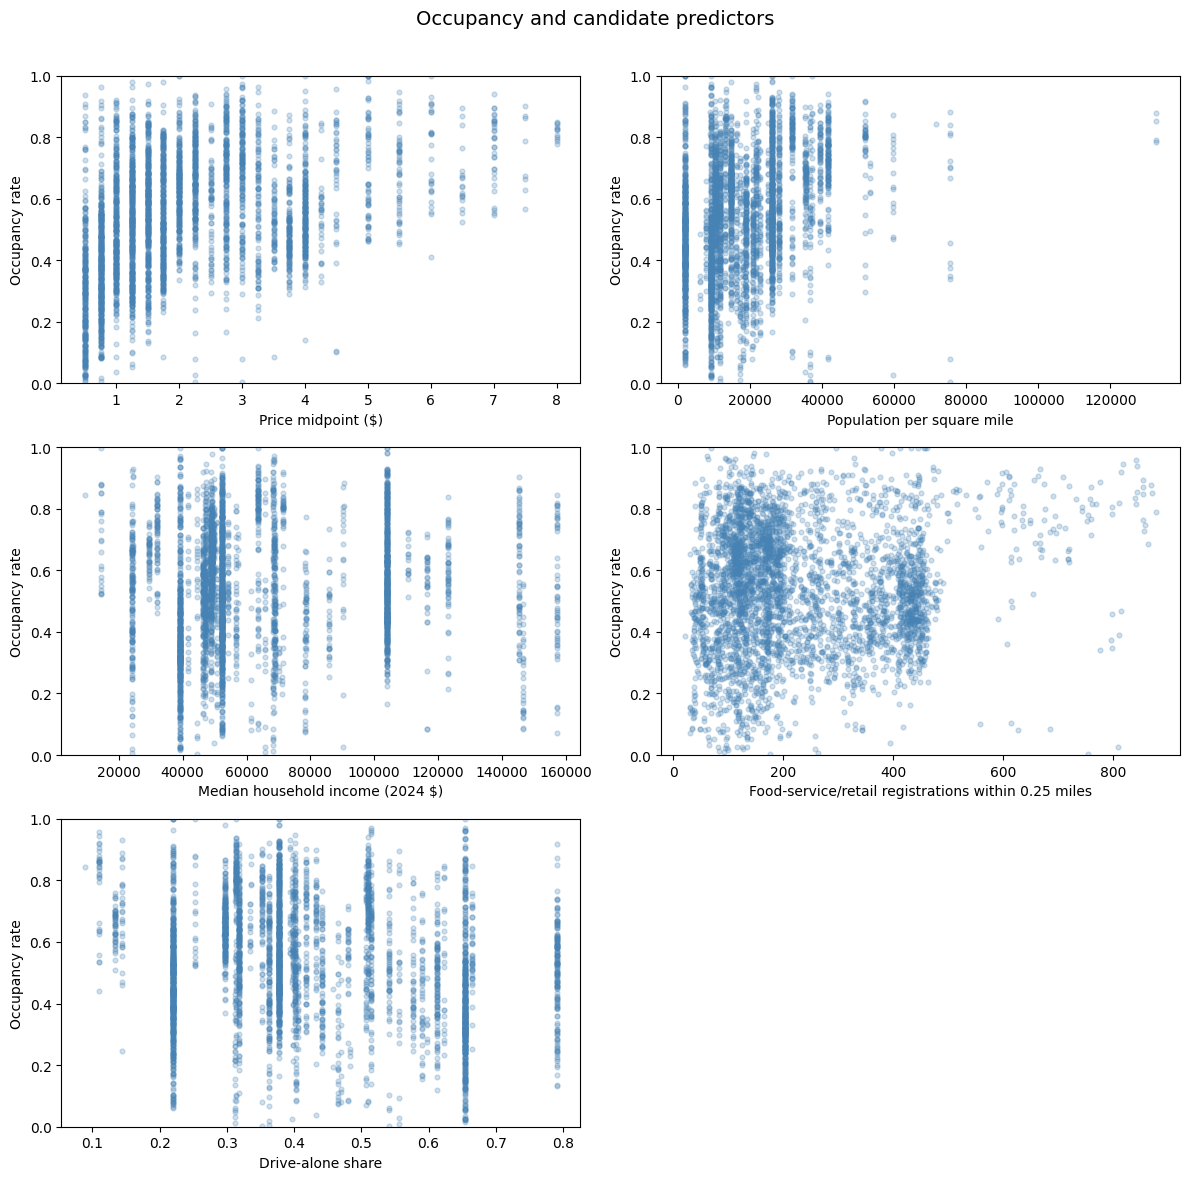

In [8]:
scatter_variables = [
    "price_midpoint", "population_density", "median_income",
    "nearby_restaurant_retail_count", "drive_alone_share"
]
scatter_labels = [
    "Price midpoint ($)", "Population per square mile",
    "Median household income (2024 $)",
    "Food-service/retail registrations within 0.25 miles",
    "Drive-alone share"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()

for i, variable in enumerate(scatter_variables):
    axes[i].scatter(
        parking[variable], parking[dependent_variable],
        s=12, alpha=0.25, color="steelblue"
    )
    axes[i].set_xlabel(scatter_labels[i])
    axes[i].set_ylabel("Occupancy rate")
    axes[i].set_ylim(0, 1)

axes[5].axis("off")
fig.suptitle("Occupancy and candidate predictors", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

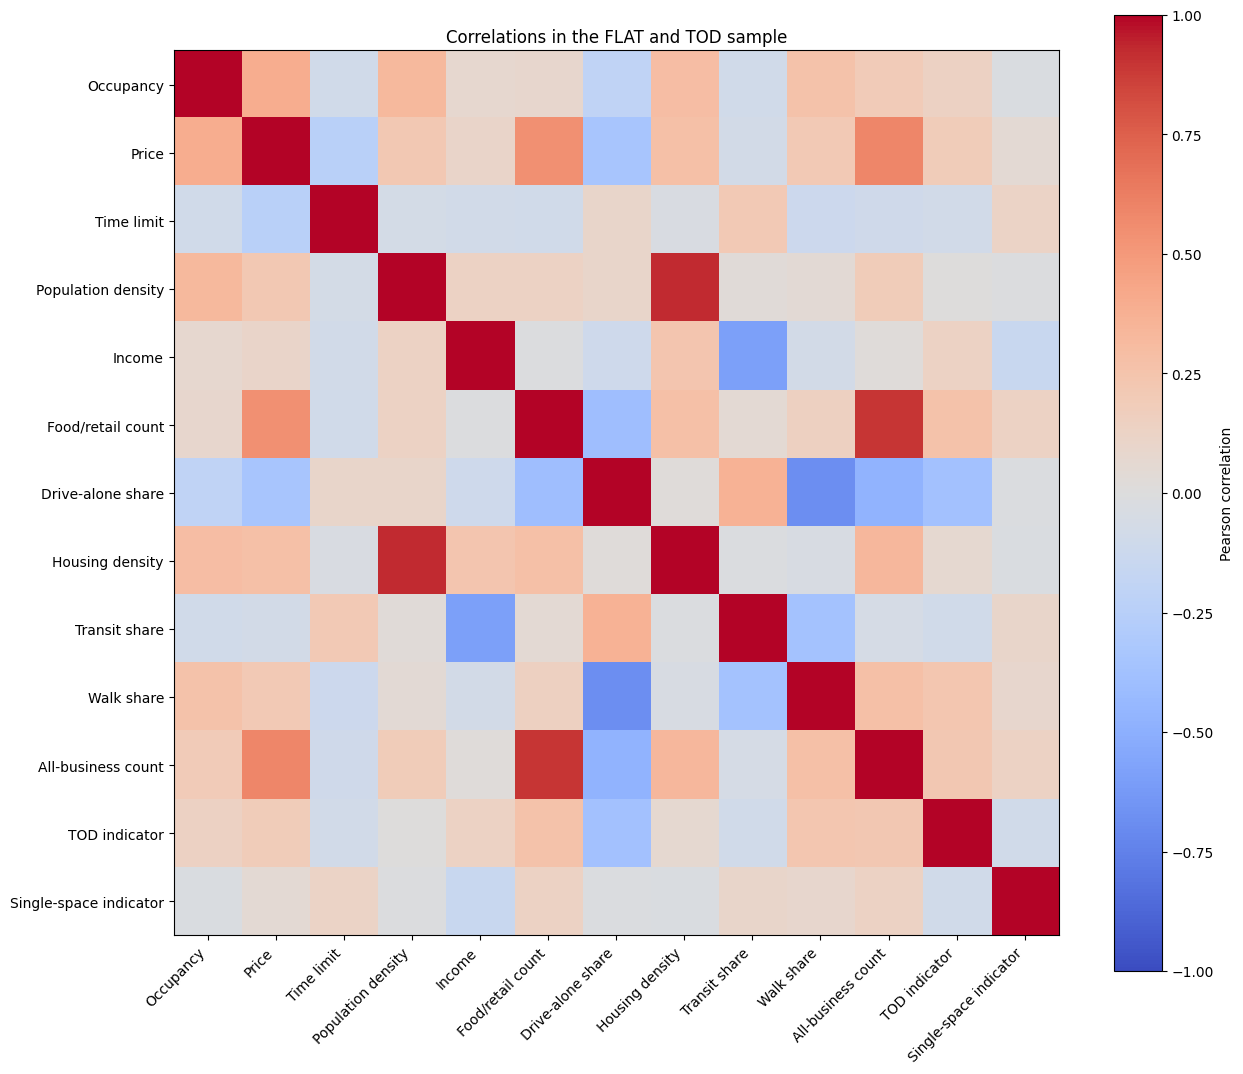

In [9]:
correlations = descriptive_data.corr()
labels = [
    "Occupancy", "Price", "Time limit", "Population density", "Income",
    "Food/retail count", "Drive-alone share", "Housing density",
    "Transit share", "Walk share", "All-business count", "TOD indicator", "Single-space indicator"
]

assert len(labels) == len(correlations)
fig, ax = plt.subplots(figsize=(13, 11))
heatmap = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
ax.set_title("Correlations in the FLAT and TOD sample")
fig.tight_layout()
plt.show()


Occupancy varies widely at the same price or density. Its correlation with price is positive (0.394), but this does not show that higher prices cause higher occupancy: higher-demand locations may also receive higher tariffs.

Population and housing density are strongly correlated (0.925), as are the two business counts (0.898). These pairs contain overlapping information that needs attention during variable selection. Correlations involving income use the available 4,016 observations; other pairs use 4,060.

<a id="section-2d"></a>

## 2(d) Q-Q Plots and Density Plots

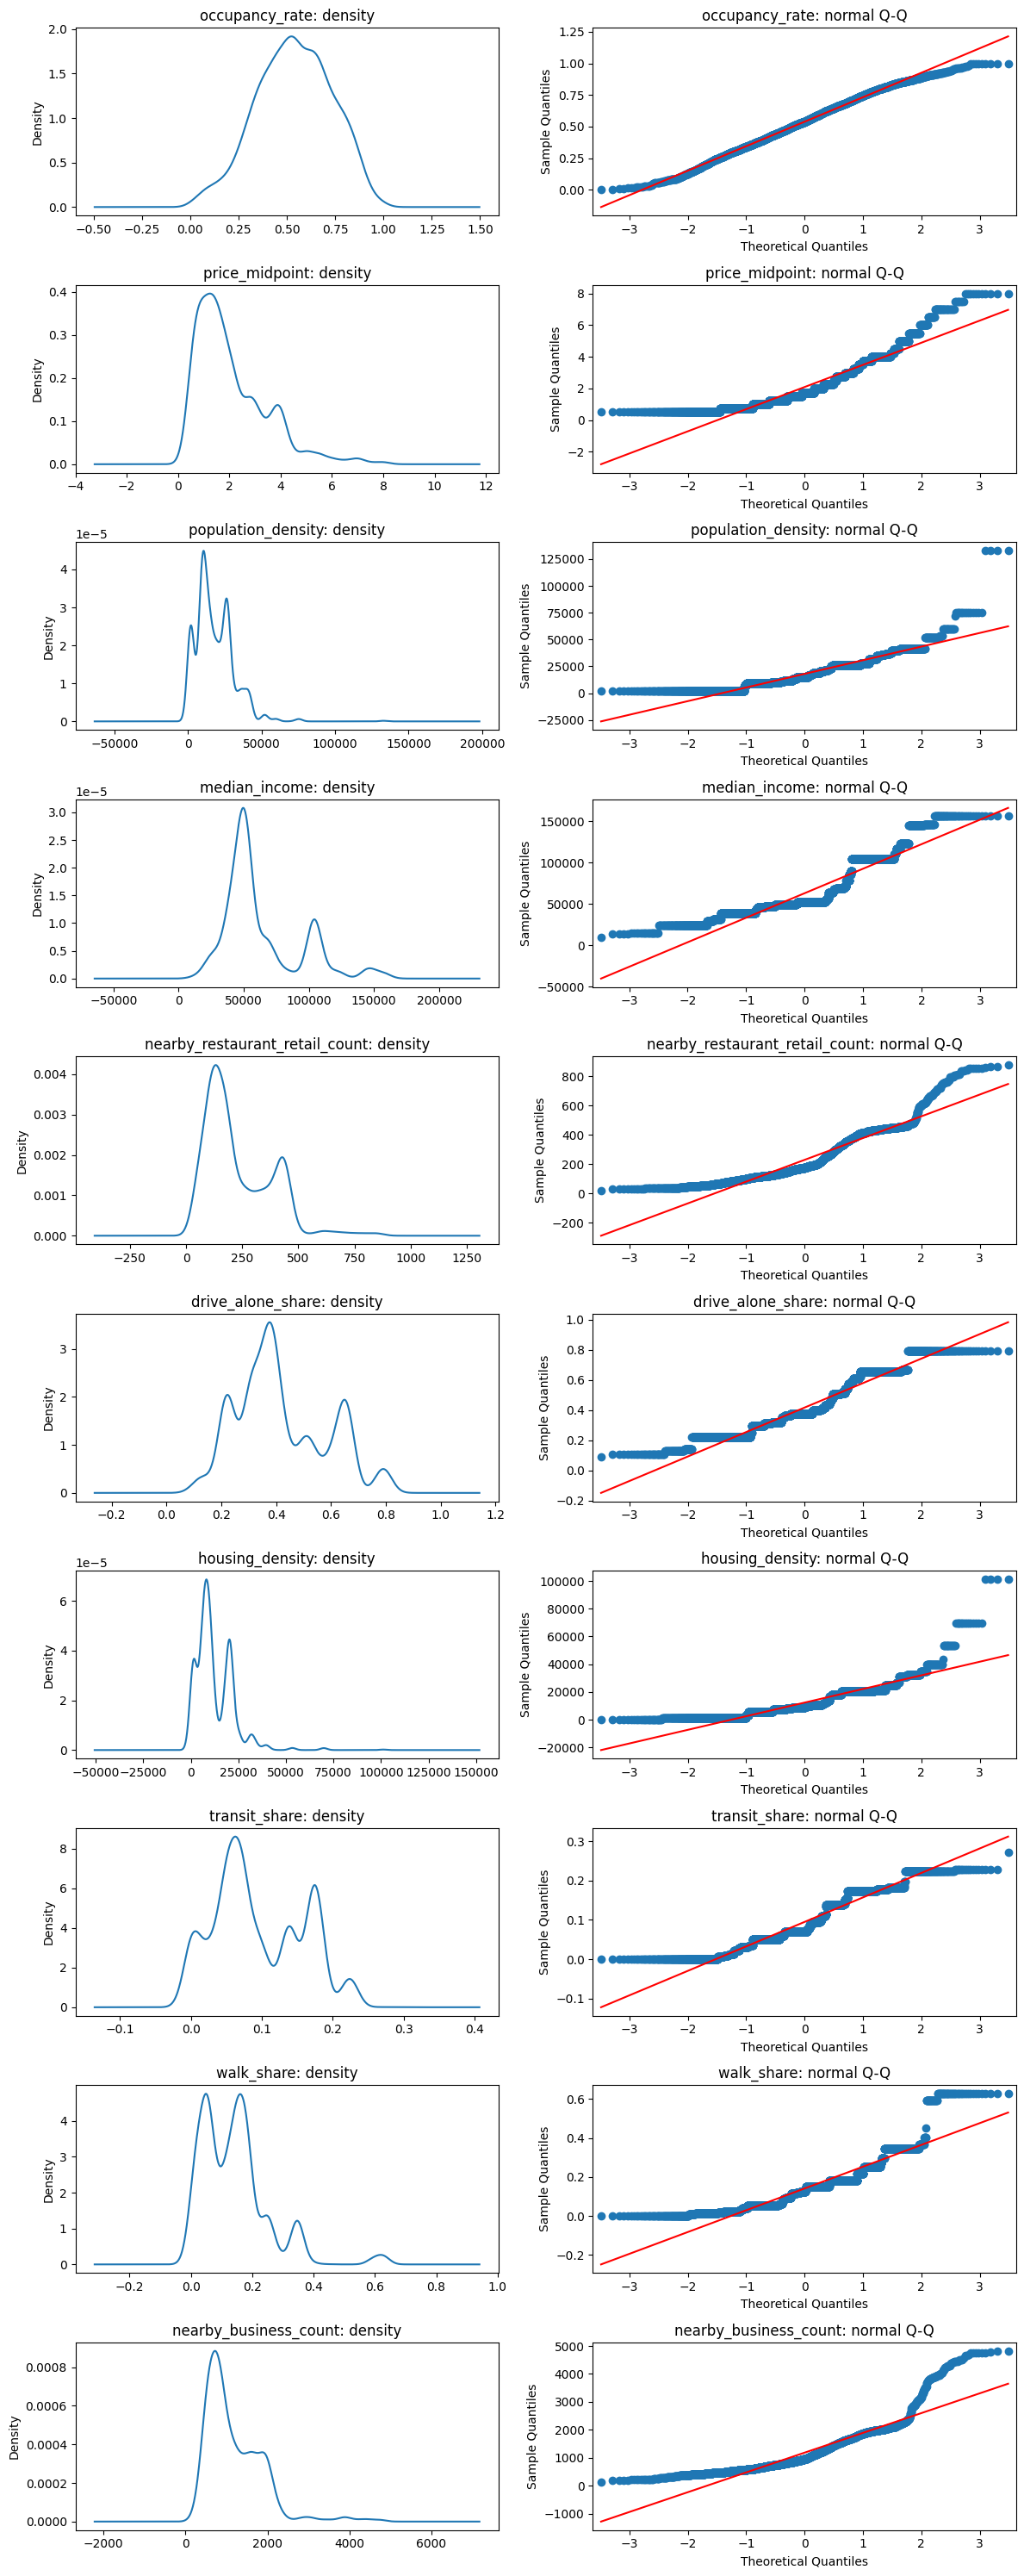

In [10]:
continuous_variables = [v for v in numeric_variables if v != "time_limit_hours"]
fig, axes = plt.subplots(len(continuous_variables), 2,
                         figsize=(12, 3 * len(continuous_variables)))

for i, variable in enumerate(continuous_variables):
    values = parking[variable].dropna()
    values.plot.density(ax=axes[i, 0])
    axes[i, 0].set_title(variable + ": density")
    sm.qqplot(values, line="s", ax=axes[i, 1])
    axes[i, 1].set_title(variable + ": normal Q-Q")

fig.tight_layout()
plt.show()


Densities, income and business counts show upper-tail departures from a normal distribution. Occupancy and commuting shares are bounded, and prices and counts take discrete values, so their smooth density curves are descriptive approximations. Time limits are discrete and are summarized in the descriptive table.

OLS does not require the predictors to be normally distributed. These plots help us consider functional form; residual normality is examined separately in [Section 4(c)](04_diagnostics_robustness.ipynb#section-4c).

<a id="section-2e"></a>

## 2(e) Nonlinearities and Possible Transformations

The scatterplots suggest that the relationship between occupancy and some predictors may not be constant across their ranges, although overlap and repeated tract values make curvature difficult to distinguish. Positive, right-skewed population density is a candidate for a natural-log transformation, which would allow diminishing changes in occupancy as density rises.

Shares can contain zeros, so taking their logs directly would be inappropriate. We keep the original units for the main regressions and compare log population density in [Section 4(a)](04_diagnostics_robustness.ipynb#section-4a), alongside the residual plots and RESET test. Natural logs are appropriate only for strictly positive values; `log1p` is a possible alternative for nonnegative registration counts because it preserves zeros. A price-squared term or spline could capture curvature if supported by diagnostics and validation. Transformations should address functional form, not merely make predictor distributions look normal.

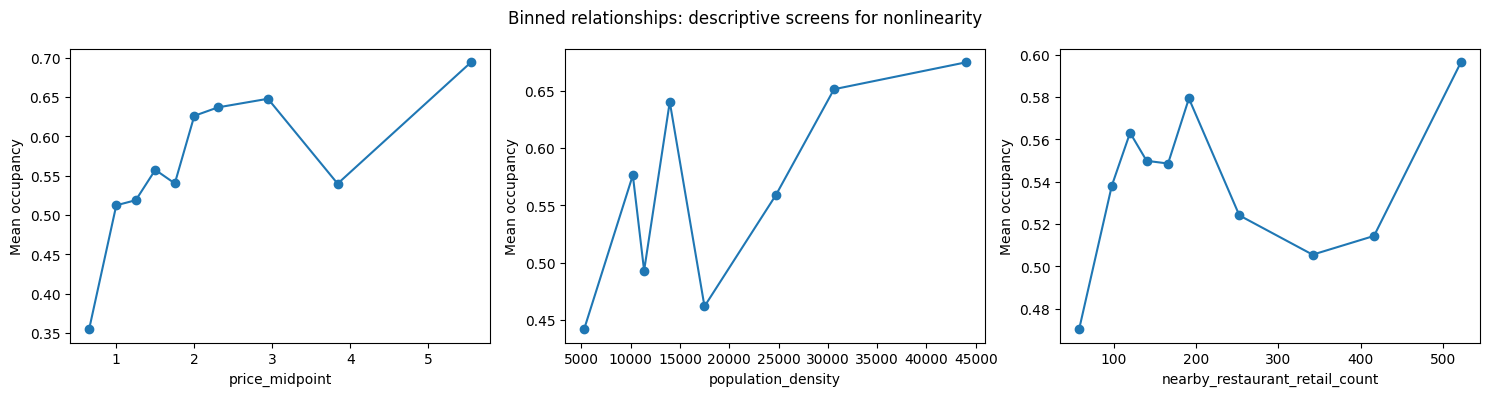

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["price_midpoint", "population_density", "nearby_restaurant_retail_count"]):
    pairs = parking[[name, "occupancy_rate"]].dropna().copy()
    pairs["bin"] = pd.qcut(pairs[name], q=10, duplicates="drop")
    means = pairs.groupby("bin", observed=True).agg(
        predictor_mean=(name, "mean"), occupancy_mean=("occupancy_rate", "mean"),
        spaces=("occupancy_rate", "size"))
    ax.plot(means.predictor_mean, means.occupancy_mean, "o-")
    ax.set(xlabel=name, ylabel="Mean occupancy")
fig.suptitle("Binned relationships: descriptive screens for nonlinearity")
fig.tight_layout()
plt.show()


The binned price relationship rises overall but dips around a four-dollar price proxy. Registration-count means are nonmonotonic, and density also shows irregular changes rather than a constant slope. These patterns motivate considering flexible functional forms, while variation in geography and sample composition can also explain them.

Binned means summarize possible curvature but mix locations and shared demand conditions. Repeated or discrete prices can produce unequal bins. They do not estimate a causal price response; residual plots and RESET assess the fitted conditional specification in Section 4.

<a id="section-2f"></a>

## 2(f) Outliers

In [12]:
q1 = parking[numeric_variables].quantile(0.25)
q3 = parking[numeric_variables].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outside_fences = (
    parking[numeric_variables].lt(lower_fence)
    | parking[numeric_variables].gt(upper_fence)
)

iqr_check = pd.DataFrame({
    "observed_count": parking[numeric_variables].count(),
    "lower_fence": lower_fence,
    "upper_fence": upper_fence,
    "outside_count": outside_fences.sum(),
    "outside_percent": outside_fences.sum() / parking[numeric_variables].count() * 100
})

iqr_check.round(3)

,observed_count,lower_fence,upper_fence,outside_count,outside_percent
occupancy_rate,4060,-0.012,1.094,0,0.000
price_midpoint,4060,-1.625,5.375,150,3.695
time_limit_hours,4060,2.000,2.000,1160,28.571
population_density,4060,-16260.332,51723.607,79,1.946
median_income,4016,11924.000,105332.000,251,6.250
nearby_restaurant_retail_count,4060,-212.500,671.500,59,1.453
drive_alone_share,4060,0.008,0.818,0,0.000
housing_density,4060,-16062.409,42621.149,36,0.887
transit_share,4060,-0.083,0.274,0,0.000
walk_share,4060,-0.134,0.371,82,2.020


In [13]:
tract_extremes = parking.groupby("GEOID").agg(
    spaces=("SpaceID", "size"),
    population_density=("population_density", "first"),
    housing_density=("housing_density", "first"),
    median_income=("median_income", "first")
)

tract_extremes.sort_values("population_density", ascending=False).head(5).round(2)

,spaces,population_density,housing_density,median_income
GEOID,,,,
06037207304,4,132736.84,101157.89,14342.0
06037207307,15,75368.42,69894.74,NaN
06037206302,1,71611.11,43222.22,9375.0
06037207308,16,59666.67,53333.33,90156.0
06037265306,6,53333.33,14861.11,57188.0


In [14]:
parking.nlargest(5, "nearby_restaurant_retail_count")[[
    "SpaceID", "BlockFace", "nearby_restaurant_retail_count",
    "nearby_business_count", "occupancy_rate"
]]

,SpaceID,BlockFace,nearby_restaurant_retail_count,nearby_business_count,occupancy_rate
1466,CB3648B,501 SPRING ST,878,4467,0.789179
1468,CB3651,601 SPRING ST,870,4457,0.851962
1465,CB3648,501 SPRING ST,868,4406,0.878580
1912,CB4371,600 SPRING ST,862,4435,0.684367
1909,CB4368,600 SPRING ST,858,4399,0.746714


The IQR screen flags 150 price values, 79 population-density values, 251 observed incomes and 59 food-service/retail counts. These observations may describe genuinely different neighborhoods. The highest densities occur in small downtown tracts, while high registration counts can include multiple accounts at the same address.

For time limits, both quartiles equal two hours, giving an IQR of zero and flagging all 1,160 non-two-hour values. This illustrates why an outlier flag is not enough to identify a data error. We retain these observations. [Section 4(d)](04_diagnostics_robustness.ipynb#section-4d) examines standardized/studentized residuals, Cook’s distance and leverage after fitting the model.

<a id="section-2g"></a>

## 2(g) Missing Values and Sensitivity Analysis

In [15]:
eda_variables = ["occupancy_rate"] + candidate_variables
missingness = pd.DataFrame({
    "Missing": parking[eda_variables].isna().sum(),
    "Percent": parking[eda_variables].isna().mean() * 100
})
display(missingness.round(2))

missing_income = parking["median_income"].isna()
display(parking[missing_income].groupby("GEOID").agg(
    spaces=("SpaceID", "size"),
    mean_occupancy=("occupancy_rate", "mean")
))
parking.groupby(missing_income)["occupancy_rate"].agg(
    ["count", "mean", "median"]
).rename_axis("Income missing")


,Missing,Percent
occupancy_rate,0,0.00
price_midpoint,0,0.00
time_limit_hours,0,0.00
population_density,0,0.00
median_income,44,1.08
nearby_restaurant_retail_count,0,0.00
drive_alone_share,0,0.00
RateType,0,0.00
MeterType,0,0.00
housing_density,0,0.00


,spaces,mean_occupancy
GEOID,,
06037207307,15,0.541551
06037265301,29,0.678567


,count,mean,median
Income missing,,,
False,4016,0.537639,0.537619
True,44,0.631857,0.687002


Income is missing for 44 spaces (1.08%), concentrated in two tracts with 15 and 29 spaces. Their mean occupancy is 0.632, compared with 0.538 for spaces with observed income, so the missingness may not be random.

We leave income missing rather than fill it with an overall average that would hide tract differences. All 4,060 spaces remain in this EDA; the regression comparison uses 4,016 common complete cases. Missing zoning does not remove observations because zoning is not included in the analysis.

The final model does not use income, so [Section 4(g)](04_diagnostics_robustness.ipynb#section-4g) checks the exclusion by restoring the 44 spaces. The price association changes from about 5.15 to 5.33 occupancy percentage points per dollar and remains positive. This supports the stability of its sign, while showing that the sample decision affects its magnitude.

### Missing-income treatment and imputation sensitivity

The primary analysis keeps observed values and uses a common complete-case sample. Because the selected final model excludes income, restoring income-missing spaces in Section 4 isolates the sample restriction without filling any final regressor.

The comparison below also evaluates an explicit imputation benchmark. Observed incomes remain unchanged; the 44 missing values receive the observed sample median, and a missing-income indicator allows their conditional level to differ. The median is less sensitive to the right tail than the mean, but does not recover the two tracts’ true incomes. Single imputation compresses variation and does not propagate imputation uncertainty. This is a sensitivity check, not the preferred data treatment or a solution to potentially nonrandom missingness.

A fixed three-predictor demand specification (price, population density and food-service/retail registrations) is used here before the selection analysis. The first pair of fits isolates the income-complete sample restriction. The second pair includes income and compares complete cases with median imputation plus its missingness indicator. Those second fits differ in both sample and missing-data treatment; they should not be interpreted as an isolated causal effect of imputation.

In [16]:
missing_base = ["price_midpoint", "population_density", "nearby_restaurant_retail_count"]
available = parking.dropna(subset=["occupancy_rate", *missing_base]).copy()
observed_income = available.dropna(subset=["median_income"]).copy()
median_income_fill = observed_income["median_income"].median()
assert pd.notna(median_income_fill)
imputed_income = available.copy()
imputed_income["income_missing"] = imputed_income["median_income"].isna().astype(int)
imputed_income["median_income"] = imputed_income["median_income"].fillna(median_income_fill)
assert imputed_income.loc[imputed_income.income_missing.eq(0), "median_income"].equals(observed_income["median_income"])
missing_fits = [
    ("Income-complete sample; no income regressor", observed_income, missing_base),
    ("All available spaces; no income regressor", available, missing_base),
    ("Complete-case income regressor", observed_income, [*missing_base, "median_income"]),
    ("Median-imputed income + missingness indicator", imputed_income,
     [*missing_base, "median_income", "income_missing"])
]
missing_rows = []
for label, frame, columns in missing_fits:
    fit = sm.OLS(frame.occupancy_rate, sm.add_constant(frame[columns])).fit(cov_type="HC1")
    interval = fit.conf_int().loc["price_midpoint"]
    missing_rows.append({"Treatment": label, "N": int(fit.nobs),
                         "Price association (pp per dollar)": 100 * fit.params["price_midpoint"],
                         "HC1 lower (pp)": 100 * interval[0],
                         "HC1 upper (pp)": 100 * interval[1]})
missing_sensitivity = pd.DataFrame(missing_rows)
display(missing_sensitivity.round(4))
display(Markdown(f"The median fill is **{median_income_fill:,.0f} dollars**, applied to **{int(imputed_income.income_missing.sum())}** spaces. Under the fixed three-predictor specification, restoring missing-income spaces changes the price association from **{missing_sensitivity.iloc[0]['Price association (pp per dollar)']:.3f}** to **{missing_sensitivity.iloc[1]['Price association (pp per dollar)']:.3f}** occupancy pp per dollar. With income included, the complete-case and imputation-benchmark associations are **{missing_sensitivity.iloc[2]['Price association (pp per dollar)']:.3f}** and **{missing_sensitivity.iloc[3]['Price association (pp per dollar)']:.3f}**. These are sensitivity comparisons, not replacements for the final Model 3. HC1 does not address imputation uncertainty or tract dependence."))


,Treatment,N,Price association (pp per dollar),HC1 lower (pp),HC1 upper (pp)
0,Income-complete sample; no income regressor,4016,5.9991,5.5656,6.4326
1,All available spaces; no income regressor,4060,6.1715,5.7315,6.6116
2,Complete-case income regressor,4016,6.0152,5.5792,6.4513
3,Median-imputed income + missingness indicator,4060,6.1882,5.7470,6.6294


The median fill is **52,412 dollars**, applied to **44** spaces. Under the fixed three-predictor specification, restoring missing-income spaces changes the price association from **5.999** to **6.172** occupancy pp per dollar. With income included, the complete-case and imputation-benchmark associations are **6.015** and **6.188**. These are sensitivity comparisons, not replacements for the final Model 3. HC1 does not address imputation uncertainty or tract dependence.

<a id="section-2h"></a>

## 2(h) Pandas Profiling

In [17]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=DeprecationWarning,
                            message=r"(?s).*import ydata_profiling.*deprecated.*")
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    from ydata_profiling import ProfileReport

profile_data = pd.get_dummies(
    parking[["occupancy_rate"] + candidate_variables], drop_first=True, dtype=int
)
from contextlib import redirect_stderr
from io import StringIO

with redirect_stderr(StringIO()):
    profile = ProfileReport(profile_data, minimal=True, progress_bar=False)
    summary = profile.description_set

print("Observations:", summary.table["n"])
print("Missing cells:", summary.table["n_cells_missing"])
pd.DataFrame({"Profiling alert": [str(alert) for alert in summary.alerts]})


Observations: 4060
Missing cells: 44


,Profiling alert
0,[median_income] 44 (1.1%) missing values
1,[occupancy_rate] has unique values
2,[transit_share] has 278 (6.8%) zeros
3,[walk_share] has 95 (2.3%) zeros
4,[RateType_TOD] has 737 (18.2%) zeros
5,[MeterType_Single-Space] has 133 (3.3%) zeros


Profiling confirms 4,060 observations and 44 missing cells, all in income. It also flags unique occupancy values and zeros in commuting shares and meter indicators. Zeros in these variables have a valid interpretation, such as no reported transit commuters or membership in the reference meter category. These alerts help identify features to inspect; they do not justify deleting or recoding observations.